In [1]:
import os
import re
import time
import json
import requests
import zipfile
import io
import numpy as np
import pandas as pd
from dotenv import load_dotenv

In [2]:
load_dotenv()
print(os.getenv("FRED_API_KEY") is not None)

True


In [3]:
url = "https://api.stlouisfed.org/fred/series"
params = {
    "series_id": "CPIAUCNS",
    "api_key": os.getenv("FRED_API_KEY"),
    "file_type": "json"
}

response = requests.get(url, params=params)
print(response.status_code)

200


In [83]:
# =========================
# LOAD API KEYS
# =========================

FRED_API_KEY = os.getenv("FRED_API_KEY")
BLS_API_KEY = os.getenv("BLS_API_KEY")  # optional but recommended

# =========================
# USER SETTINGS
# =========================
WEIGHTS_XLSX = "cpi-u-historical-cost-weights.xlsx"
TARGET_SERIES = "CUUR0000SA0"   # BLS NSA headline CPI-U all items
START_DATE = "2011-12-01"       # include Dec 2011 so Jan 2012 can be chained
END_DATE = None                 # None = latest available
DROP_MISSING_INDEX_ROWS = True

SERIES_OVERRIDES = {
    # Add manual fixes here if needed
    # Example:
    # "SETA02": "CUUR0000SETA02",
}

BLS_URL = "https://api.bls.gov/publicAPI/v2/timeseries/data/"

# =========================
# HELPERS
# =========================
def make_nsa_cpi_series_id(item_code):
    return SERIES_OVERRIDES.get(item_code, f"CUUR0000{item_code}")

def fetch_bls_series(series_ids, start_year, end_year, bls_api_key=None):
    payload = {
        "seriesid": series_ids,
        "startyear": str(start_year),
        "endyear": str(end_year),
    }
    if bls_api_key:
        payload["registrationkey"] = bls_api_key

    r = requests.post(
        BLS_URL,
        data=json.dumps(payload),
        headers={"Content-type": "application/json"},
        timeout=60
    )
    r.raise_for_status()
    data = r.json()

    status = data.get("status")
    if status != "REQUEST_SUCCEEDED":
        raise ValueError(data)

    rows = []
    returned_series = data.get("Results", {}).get("series", [])

    for s in returned_series:
        sid = s.get("seriesID")
        observations = s.get("data", [])

        for obs in observations:
            period = obs.get("period", "")
            if period.startswith("M") and period != "M13":
                rows.append({
                    "series_id": sid,
                    "date": pd.Timestamp(
                        year=int(obs["year"]),
                        month=int(period[1:]),
                        day=1
                    ),
                    "value": pd.to_numeric(obs.get("value"), errors="coerce")
                })

    return pd.DataFrame(rows)

def fetch_bls_one_series_wide(series_id, start_year, end_year, bls_api_key=None):
    df = fetch_bls_series([series_id], start_year, end_year, bls_api_key=bls_api_key)
    if df.empty:
        raise ValueError(f"No observations returned for {series_id}")
    out = df[["date", "value"]].rename(columns={"value": series_id}).sort_values("date")
    return out

# =========================
# LOAD WEIGHT SHEETS
# =========================
xls = pd.ExcelFile(WEIGHTS_XLSX)
weight_sheets = sorted([s for s in xls.sheet_names if re.fullmatch(r"\d{6}", str(s))])

if not weight_sheets:
    raise ValueError("No YYYYMM weight sheets found in workbook.")

def load_weight_sheet(sheet):
    df = pd.read_excel(WEIGHTS_XLSX, sheet_name=sheet, header=1)
    df.columns = [str(c).strip() for c in df.columns]

    code_col = [c for c in df.columns if "Item Code" in c][0]
    title_col = [c for c in df.columns if "Item Title" in c][0]
    cw_col = [c for c in df.columns if "CPI-U Cost Weight" in c][0]
    idx_col = [c for c in df.columns if "CPI-U Index Level" in c][0]
    ri_col = [c for c in df.columns if "CPI-U Relative Importance" in c][0]

    out = df[[code_col, title_col, cw_col, idx_col, ri_col]].copy()
    out.columns = ["item_code", "item_title", "cost_weight_dec", "index_level_dec", "relative_importance_dec"]
    out["sheet"] = sheet
    out["cost_weight_dec"] = pd.to_numeric(out["cost_weight_dec"], errors="coerce")
    out["index_level_dec"] = pd.to_numeric(out["index_level_dec"], errors="coerce")
    out["relative_importance_dec"] = pd.to_numeric(out["relative_importance_dec"], errors="coerce")
    return out

weights_by_sheet = {s: load_weight_sheet(s) for s in weight_sheets}

# =========================
# BUILD COMPONENT UNIVERSE
# =========================
base_sheet = weight_sheets[0]
base_weights = weights_by_sheet[base_sheet].copy()

base_weights = base_weights[base_weights["item_code"] != "SA0"].copy()
base_weights = base_weights[base_weights["cost_weight_dec"].fillna(0) > 0].copy()

if DROP_MISSING_INDEX_ROWS:
    base_weights = base_weights[base_weights["index_level_dec"].notna()].copy()

base_weights["series_id"] = base_weights["item_code"].map(make_nsa_cpi_series_id)

# =========================
# DOWNLOAD TARGET CPI
# =========================
start_year = pd.Timestamp(START_DATE).year
end_year = pd.Timestamp.today().year if END_DATE is None else pd.Timestamp(END_DATE).year

target = fetch_bls_one_series_wide(
    TARGET_SERIES,
    start_year=start_year,
    end_year=end_year,
    bls_api_key=BLS_API_KEY
)
target = target.rename(columns={TARGET_SERIES: "official_cpi"})
target = target[target["date"] >= pd.Timestamp(START_DATE)].copy()
if END_DATE is not None:
    target = target[target["date"] <= pd.Timestamp(END_DATE)].copy()

# =========================
# DOWNLOAD COMPONENT SERIES
# =========================
components = base_weights[["item_code", "item_title", "series_id"]].drop_duplicates().reset_index(drop=True)

all_component_ids = components["series_id"].drop_duplicates().tolist()

series_meta = []
failed = []
series_frames = []

for i in range(0, len(all_component_ids), 50):
    batch_ids = all_component_ids[i:i+50]

    try:
        batch_long = fetch_bls_series(
            batch_ids,
            start_year=start_year,
            end_year=end_year,
            bls_api_key=BLS_API_KEY
        )

        returned_ids = set(batch_long["series_id"].unique()) if not batch_long.empty else set()

        for sid in batch_ids:
            if sid not in returned_ids:
                failed.append((sid, "not returned by BLS API"))

        if not batch_long.empty:
            batch_wide = (
                batch_long
                .pivot_table(index="date", columns="series_id", values="value", aggfunc="first")
                .reset_index()
                .sort_values("date")
            )
            series_frames.append(batch_wide)

            for sid in returned_ids:
                meta_row = components.loc[components["series_id"] == sid].iloc[0]
                series_meta.append({
                    "item_code": meta_row["item_code"],
                    "item_title": meta_row["item_title"],
                    "series_id": sid,
                })

        time.sleep(0.2)

    except Exception as e:
        for sid in batch_ids:
            failed.append((sid, str(e)))

if not series_frames:
    raise ValueError("No component series were successfully downloaded from the BLS API.")

comp_df = series_frames[0].copy()
for df in series_frames[1:]:
    comp_df = comp_df.merge(df, on="date", how="outer")

comp_df = comp_df.sort_values("date").reset_index(drop=True)
comp_df = comp_df[comp_df["date"] >= pd.Timestamp(START_DATE)].copy()
if END_DATE is not None:
    comp_df = comp_df[comp_df["date"] <= pd.Timestamp(END_DATE)].copy()

# =========================
# DEFINE WEIGHT REGIMES
# =========================
sheet_to_start = {}
for s in weight_sheets:
    dec_date = pd.to_datetime(s, format="%Y%m")
    start_date = dec_date + pd.offsets.MonthBegin(1)
    sheet_to_start[s] = start_date

regimes = []
for i, s in enumerate(weight_sheets):
    start = sheet_to_start[s]
    if i < len(weight_sheets) - 1:
        next_start = sheet_to_start[weight_sheets[i + 1]]
        end = next_start - pd.offsets.MonthBegin(1)
    else:
        end = pd.Timestamp.max.normalize()
    regimes.append((s, start, end))

# =========================
# RECONSTRUCTION
# =========================
def reconstruct_regime(sheet_name, start, end, comp_df):
    w = weights_by_sheet[sheet_name].copy()
    w = w[w["item_code"] != "SA0"].copy()
    w = w[w["cost_weight_dec"].fillna(0) > 0].copy()

    if DROP_MISSING_INDEX_ROWS:
        w = w[w["index_level_dec"].notna()].copy()

    w["series_id"] = w["item_code"].map(make_nsa_cpi_series_id)

    available_series = [
        c for c in comp_df.columns
        if c != "date"
    ]

    w = w[w["series_id"].isin(available_series)].copy()

    if w.empty:
        return pd.DataFrame(columns=[
            "date",
            "reconstructed_cpi",
            "sheet",
            "component_count",
            "segment"
        ])

    cols = ["date"] + w["series_id"].tolist()

    block = comp_df.loc[
        (comp_df["date"] >= start - pd.offsets.MonthBegin(1)) &
        (comp_df["date"] <= end),
        cols
    ].copy()

    block = block.sort_values("date").reset_index(drop=True)
    values = block.set_index("date")

    dec_weights = (
        w.set_index("series_id")["cost_weight_dec"]
        .astype(float)
    )

    all_items_level_dec = weights_by_sheet[sheet_name].loc[
        weights_by_sheet[sheet_name]["item_code"] == "SA0",
        "index_level_dec"
    ].iloc[0]

    results = []
    current_weights = dec_weights.copy()
    current_index = float(all_items_level_dec)

    dates = list(values.index)

    for t in range(1, len(dates)):
        prev_date = dates[t - 1]
        curr_date = dates[t]

        # Explicitly mark October 2025 as unavailable.
        if curr_date == pd.Timestamp("2025-10-01"):
            results.append({
                "date": curr_date,
                "reconstructed_cpi": np.nan,
                "sheet": sheet_name,
                "component_count": 0,
                "segment": "missing_october_2025"
            })
            continue

        # Do not calculate from a month that is officially unavailable.
        if prev_date == pd.Timestamp("2025-10-01"):
            results.append({
                "date": curr_date,
                "reconstructed_cpi": np.nan,
                "sheet": sheet_name,
                "component_count": 0,
                "segment": "post_october_break"
            })
            continue

        prev_vals = values.loc[prev_date]
        curr_vals = values.loc[curr_date]

        relatives = curr_vals / prev_vals
        relatives = relatives.replace([np.inf, -np.inf], np.nan)

        valid = relatives.notna() & current_weights.notna()
        valid_count = int(valid.sum())

        # Prevent partial-basket reconstruction.
        if valid_count < 100:
            results.append({
                "date": curr_date,
                "reconstructed_cpi": np.nan,
                "sheet": sheet_name,
                "component_count": valid_count,
                "segment": "insufficient_coverage"
            })
            continue

        updated_weights = current_weights[valid] * relatives[valid]
        aggregate_relative = (
            updated_weights.sum() /
            current_weights[valid].sum()
        )

        current_index = current_index * aggregate_relative

        full_updated_weights = current_weights.copy()
        full_updated_weights.loc[valid] = updated_weights
        current_weights = full_updated_weights

        results.append({
            "date": curr_date,
            "reconstructed_cpi": current_index,
            "sheet": sheet_name,
            "component_count": valid_count,
            "segment": "continuous"
        })

    return pd.DataFrame(results)

reconstructed_parts = []
for sheet_name, start, end in regimes:
    part = reconstruct_regime(sheet_name, start, end, comp_df)
    reconstructed_parts.append(part)

reconstructed = pd.concat(reconstructed_parts, ignore_index=True).sort_values("date")
reconstructed = reconstructed[reconstructed["date"] >= pd.Timestamp("2012-01-01")].copy()

# Handle the October 2025 break as a separate segment
oct_2025 = pd.Timestamp("2025-10-01")
nov_2025 = pd.Timestamp("2025-11-01")
dec_2025 = pd.Timestamp("2025-12-01")

# Blank out the break months
reconstructed.loc[reconstructed["date"].isin([oct_2025, nov_2025]), "reconstructed_cpi"] = np.nan

# Re-anchor December 2025 to the official CPI
dec_value = target.loc[target["date"] == dec_2025, "official_cpi"]
if len(dec_value) == 1:
    reconstructed.loc[reconstructed["date"] == dec_2025, "reconstructed_cpi"] = float(dec_value.iloc[0])

    # Rebuild Jan 2026 onward from the Dec 2025 anchor using month-to-month growth
    future_mask = reconstructed["date"] > dec_2025
    future_dates = reconstructed.loc[future_mask, "date"].sort_values().tolist()

    prev_level = float(dec_value.iloc[0])

    for d in future_dates:
        prev_month = d - pd.offsets.MonthBegin(1)

        curr_row = reconstructed.loc[reconstructed["date"] == d]
        prev_row = reconstructed.loc[reconstructed["date"] == prev_month]

        if len(curr_row) == 0 or len(prev_row) == 0:
            reconstructed.loc[reconstructed["date"] == d, "reconstructed_cpi"] = np.nan
            continue

        curr_raw = curr_row["reconstructed_cpi"].iloc[0]
        prev_raw = prev_row["reconstructed_cpi"].iloc[0]

        if pd.isna(curr_raw) or pd.isna(prev_raw) or prev_raw == 0:
            reconstructed.loc[reconstructed["date"] == d, "reconstructed_cpi"] = np.nan
            continue

        growth = curr_raw / prev_raw
        prev_level = prev_level * growth

        reconstructed.loc[reconstructed["date"] == d, "reconstructed_cpi"] = prev_level

# =========================
# COMPARE TO OFFICIAL CPI
# =========================
comparison = reconstructed.merge(target, on="date", how="left")
comparison["error"] = comparison["reconstructed_cpi"] - comparison["official_cpi"]
comparison["abs_error"] = comparison["error"].abs()
comparison["pct_error"] = comparison["error"] / comparison["official_cpi"] * 100

# =========================
# SAVE OUTPUTS
# =========================
comparison.to_csv("cpi_reconstruction_comparison.csv", index=False)
pd.DataFrame(series_meta).to_csv("component_series_metadata.csv", index=False)
pd.DataFrame(failed, columns=["series_id", "reason"]).to_csv("failed_or_filtered_series.csv", index=False)

summary = {
    "target_series": TARGET_SERIES,
    "start_date": str(comparison["date"].min().date()) if len(comparison) else None,
    "end_date": str(comparison["date"].max().date()) if len(comparison) else None,
    "rows": int(len(comparison)),
    "mean_abs_error": float(comparison["abs_error"].mean()) if len(comparison) else None,
    "max_abs_error": float(comparison["abs_error"].max()) if len(comparison) else None,
    "component_series_used": int(len(series_meta)),
    "component_series_failed_or_filtered": int(len(failed)),
    "weight_sheets_found": weight_sheets,
}
with open("cpi_reconstruction_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

#print(json.dumps(summary, indent=2, default=str))
#print("\nTop failed/filtered series:")
#print(pd.DataFrame(failed, columns=["series_id", "reason"]).head(20))
#print("\nLast rows of comparison:")
#print(comparison.tail())
print("Done")

Done


In [84]:
# Create a clean two-column dataframe indexed by date
cpi_comparison = (
    comparison[
        ["date", "official_cpi", "reconstructed_cpi"]
    ]
    .rename(columns={
        "official_cpi": "CPI",
        "reconstructed_cpi": "Reconstructed_CPI"
    })
    .set_index("date")
    .sort_index()
)

cpi_comparison["CPI"] = cpi_comparison["CPI"].round(1)
cpi_comparison["Reconstructed_CPI"] = cpi_comparison["Reconstructed_CPI"].round(1)
print(cpi_comparison.tail())

              CPI  Reconstructed_CPI
date                                
2026-04-01  333.0              333.0
2026-05-01  335.1              335.2
2026-06-01  334.0              333.9
2026-07-01  333.9              333.8
2026-08-01  335.0              334.9


In [114]:
## Summary table with statistics

RMSE = np.sqrt(((cpi_comparison["Reconstructed_CPI"]-cpi_comparison["CPI"])**2).mean())
MAE = abs((cpi_comparison["Reconstructed_CPI"]-cpi_comparison["CPI"])).mean()
max_error = (cpi_comparison["Reconstructed_CPI"]-cpi_comparison["CPI"]).max()

df_stats = pd.DataFrame({'RMSE': [RMSE],
                         'MAE': [MAE],
                         'max_error': [max_error]
                       }, index=["Value"])
df_stats

,RMSE,MAE,max_error
Value,0.109334,0.073563,0.2


In [85]:
# Metadata for the component series
component_series_metadata = (
    pd.DataFrame(series_meta)
    .drop_duplicates()
    .sort_values("series_id")
    .reset_index(drop=True)
)

# Wide monthly component panel
component_panel_wide = (
    comp_df
    .copy()
    .sort_values("date")
    .set_index("date")
)

component_panel_wide = component_panel_wide.loc[
    component_panel_wide.index >= pd.Timestamp("2012-01-01")
].copy()

# Main dataframe: official CPI, reconstructed CPI, and all subcomponents
full_cpi_df = (
    cpi_comparison
    .join(component_panel_wide, how="outer")
    .sort_index()
)

# Optional long-format version for analysis
component_panel_long = (
    component_panel_wide
    .reset_index()
    .melt(
        id_vars="date",
        var_name="series_id",
        value_name="index_value"
    )
    .merge(
        component_series_metadata,
        on="series_id",
        how="left"
    )
    .sort_values(["date", "series_id"])
    .reset_index(drop=True)
)

print("full_cpi_df shape:", full_cpi_df.shape)
print("component_panel_wide shape:", component_panel_wide.shape)
print("component_panel_long shape:", component_panel_long.shape)

full_cpi_df shape: (176, 184)
component_panel_wide shape: (176, 182)
component_panel_long shape: (32032, 5)


In [86]:
full_cpi_df

,CPI,Reconstructed_CPI,CUUR0000SEAA01,CUUR0000SEAA02,CUUR0000SEAA03,CUUR0000SEAA04,CUUR0000SEAB,CUUR0000SEAC01,CUUR0000SEAC02,CUUR0000SEAC03,...,CUUR0000SETC02,CUUR0000SETD01,CUUR0000SETD02,CUUR0000SETD03,CUUR0000SETE,CUUR0000SETF01,CUUR0000SETF03,CUUR0000SETG01,CUUR0000SETG02,CUUR0000SETG03
date,,,,,,,,,,,,,,,,,,,,,
2012-01-01,226.7,226.7,116.618,148.547,80.484,116.214,96.270,94.998,99.374,80.857,...,157.206,262.293,231.441,158.847,395.974,167.301,179.128,295.429,149.440,275.852
2012-02-01,227.7,227.7,114.095,148.183,79.169,119.946,97.147,93.266,115.541,83.496,...,157.225,262.770,231.845,159.250,395.516,166.788,179.503,298.477,148.550,277.207
2012-03-01,229.4,229.5,117.054,149.106,80.036,122.690,103.211,94.265,137.535,86.978,...,158.305,263.542,232.217,158.606,396.393,166.855,179.518,303.843,149.394,279.208
2012-04-01,230.1,230.2,117.563,150.584,83.395,121.923,105.177,96.851,131.786,90.600,...,158.013,263.748,232.453,158.385,397.507,166.500,179.836,312.845,151.337,279.376
2012-05-01,229.8,229.9,119.010,155.044,81.525,123.872,102.903,87.228,126.946,90.952,...,158.857,264.157,232.982,159.041,398.478,166.500,180.147,317.066,151.912,279.728
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-04-01,333.0,333.0,93.958,196.140,86.741,143.092,121.034,106.696,114.246,79.289,...,227.019,NaN,385.137,298.065,894.315,208.967,244.807,308.527,155.521,366.011
2026-05-01,335.1,335.2,96.276,195.271,84.608,144.355,120.035,103.325,109.512,78.137,...,226.318,459.736,386.901,300.925,877.278,208.942,246.431,329.824,155.533,357.598
2026-06-01,334.0,333.9,95.790,195.947,82.275,142.520,118.983,101.155,108.266,77.066,...,228.526,NaN,389.337,306.710,858.481,208.915,244.155,323.758,154.871,363.397


In [16]:
##Saving both df to csv for later use in case API isn't working
full_cpi_df.to_csv("full_cpi_reconstruction.csv")
cpi_comparison.to_csv("Actual vs Reconstructed CPI.csv")

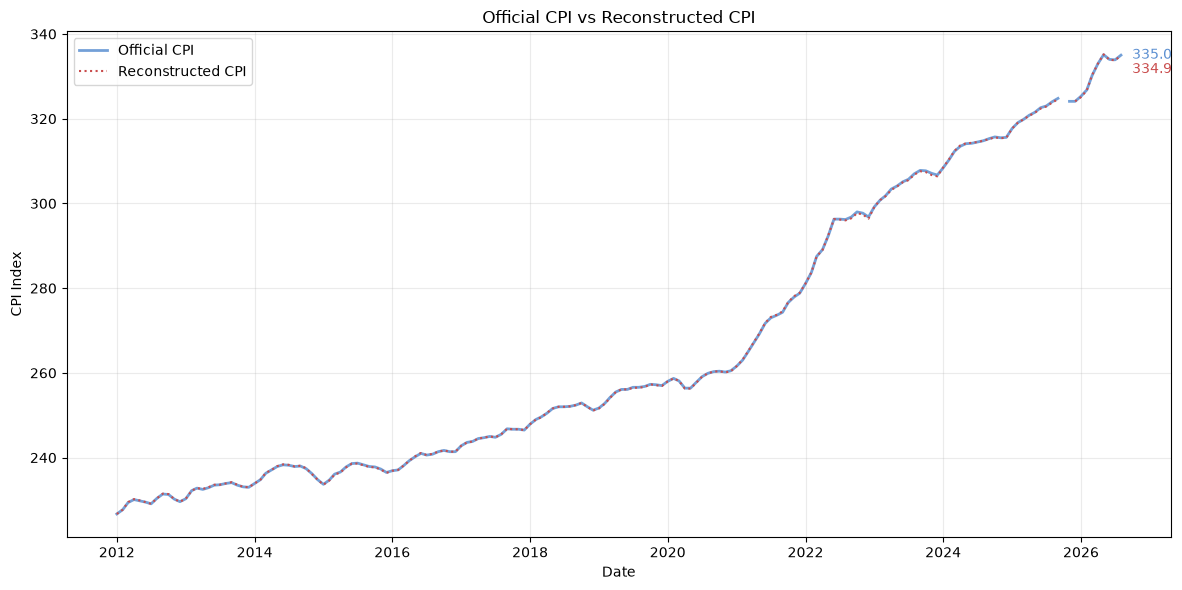

In [87]:
import matplotlib.pyplot as plt

cpi_comparison.index = pd.to_datetime(cpi_comparison.index)
cpi_comparison = cpi_comparison.sort_index()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    cpi_comparison.index,
    cpi_comparison["CPI"],
    color="#5B8FD1",
    linewidth=2.0,
    alpha=0.85,
    label="Official CPI"
)

ax.plot(
    cpi_comparison.index,
    cpi_comparison["Reconstructed_CPI"],
    color="#C94C4C",
    linestyle=":",
    linewidth=1.5,
    label="Reconstructed CPI"
)

# Last valid point for official CPI
official_last = cpi_comparison["CPI"].dropna()
x1 = official_last.index[-1]
y1 = official_last.iloc[-1]

ax.annotate(
    f"{y1:.1f}",
    xy=(x1, y1),
    xytext=(8, 0),
    textcoords="offset points",
    color="#5B8FD1",
    fontsize=10,
    va="center"
)

# Last valid point for reconstructed CPI
recon_last = cpi_comparison["Reconstructed_CPI"].dropna()
x2 = recon_last.index[-1]
y2 = recon_last.iloc[-1]

ax.annotate(
    f"{y2:.1f}",
    xy=(x2, y2),
    xytext=(8, -10),
    textcoords="offset points",
    color="#C94C4C",
    fontsize=10,
    va="center"
)

ax.set_title("Official CPI vs Reconstructed CPI")
ax.set_xlabel("Date")
ax.set_ylabel("CPI Index")
ax.legend()
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

## Federal Government Shutdown
BLS did not collect survey data for October 2025 due to a lapse in appropriations. BLS was unable to
retroactively collect these data. For a few indexes, BLS uses nonsurvey data sources instead of
survey data to make the index calculations. BLS was able to retroactively acquire most of the
nonsurvey data for October. CPI data collection resumed on November 14, 2025.
Additional information about the impact of the shutdown on CPI data is available online at
https://www.bls.gov/cpi/additional-resources/2025-federal-government-shutdown-impact-cpi.htm

In [88]:
cpi_for_seasonal = (
    full_cpi_df["CPI"]
    .copy()
    .sort_index()
    .asfreq("MS")
)

missing_dates = cpi_for_seasonal[cpi_for_seasonal.isna()].index

print(missing_dates)

DatetimeIndex(['2025-10-01'], dtype='datetime64[us]', name='date', freq='MS')


In [89]:
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
import ipywidgets as widgets
from IPython.display import display
from statsmodels.tools.sm_exceptions import ConvergenceWarning, ValueWarning

base_df = full_cpi_df.copy()
base_df.index = pd.to_datetime(base_df.index)
base_df = base_df.sort_index().asfreq("MS")

default_end = base_df.index.max()
default_start = default_end - pd.DateOffset(years=5) + pd.DateOffset(months=1)

month_options = [(d.strftime("%Y-%m"), d) for d in base_df.index]

start_dropdown = widgets.Dropdown(
    options=month_options,
    value=default_start,
    description="Start:",
    layout=widgets.Layout(width="180px")
)

end_dropdown = widgets.Dropdown(
    options=month_options,
    value=default_end,
    description="End:",
    layout=widgets.Layout(width="180px")
)

run_button = widgets.Button(
    description="Compute seasonal factors",
    button_style="primary",
    layout=widgets.Layout(width="230px", height="40px")
)

output = widgets.Output()

seasonal_factors = None
seasonal_log_components = None
model_results = None
failed_series = None
non_converged = None

@output.capture(clear_output=True)
def compute_seasonal_factors(_):
    global seasonal_factors, seasonal_log_components
    global model_results, failed_series, non_converged

    run_button.disabled = True
    run_button.description = "Running..."

    try:
        start_date = pd.Timestamp(start_dropdown.value)
        end_date = pd.Timestamp(end_dropdown.value)

        if start_date > end_date:
            print("Start date must be before end date.")
            return

        series_df = base_df.loc[
            (base_df.index >= start_date) &
            (base_df.index <= end_date)
        ].copy()

        seasonal_factors_dict = {}
        seasonal_log_components_dict = {}
        model_results = {}
        failed_series = {}
        non_converged = []

        for column in series_df.columns:
            series = series_df[column].copy()

            if series.notna().sum() < 24:
                failed_series[column] = "fewer than 24 observations"
                continue

            if (series.dropna() <= 0).any():
                failed_series[column] = "contains zero or negative values"
                continue

            log_series = np.log(series)

            try:
                model = sm.tsa.UnobservedComponents(
                    log_series,
                    level="local linear trend",
                    seasonal=12,
                    stochastic_seasonal=False
                )

                with warnings.catch_warnings():
                    warnings.filterwarnings("ignore", category=ConvergenceWarning)
                    warnings.filterwarnings("ignore", category=ValueWarning)

                    results = model.fit(
                        disp=False,
                        maxiter=2000
                    )

                mle_retvals = results.mle_retvals

                converged = (
                    mle_retvals.get("converged")
                    if "converged" in mle_retvals
                    else mle_retvals.get("warnflag", 0) == 0
                )

                if not converged:
                    non_converged.append(column)

                seasonal_output = results.seasonal

                if hasattr(seasonal_output, "smoothed"):
                    seasonal_log = seasonal_output.smoothed
                else:
                    seasonal_log = seasonal_output

                seasonal_log = pd.Series(
                    np.asarray(seasonal_log).squeeze(),
                    index=series.index,
                    name=column
                )

                seasonal_log_components_dict[column] = seasonal_log
                seasonal_factors_dict[column] = np.exp(seasonal_log)
                model_results[column] = results

            except Exception as error:
                failed_series[column] = repr(error)

        if seasonal_log_components_dict:
            seasonal_log_components = pd.concat(seasonal_log_components_dict, axis=1)
        else:
            seasonal_log_components = pd.DataFrame(index=series_df.index)

        if seasonal_factors_dict:
            seasonal_factors = pd.concat(seasonal_factors_dict, axis=1)
        else:
            seasonal_factors = pd.DataFrame(index=series_df.index)

        print("Date range:", start_date.date(), "to", end_date.date())
        print("Seasonal factors shape:", seasonal_factors.shape)
        print("Non-converged series:", len(non_converged))
        print("Failed series:", len(failed_series))

    finally:
        run_button.disabled = False
        run_button.description = "Compute seasonal factors"

run_button.on_click(compute_seasonal_factors, remove=True)
run_button.on_click(compute_seasonal_factors)

display(
    widgets.HBox(
        [start_dropdown, end_dropdown, run_button],
        layout=widgets.Layout(gap="10px", align_items="center")
    )
)
display(output)

Output()

In [90]:
one_set_of_factors = seasonal_factors.groupby(
    seasonal_factors.index.month
).mean()
one_set_of_factors

,CPI,Reconstructed_CPI,CUUR0000SEAA01,CUUR0000SEAA02,CUUR0000SEAA03,CUUR0000SEAA04,CUUR0000SEAB,CUUR0000SEAC01,CUUR0000SEAC02,CUUR0000SEAC03,...,CUUR0000SETC02,CUUR0000SETD01,CUUR0000SETD02,CUUR0000SETD03,CUUR0000SETE,CUUR0000SETF01,CUUR0000SETF03,CUUR0000SETG01,CUUR0000SETG02,CUUR0000SETG03
date,,,,,,,,,,,,,,,,,,,,,
1,0.995060,0.995181,0.994553,1.001358,0.985163,1.005889,0.995123,0.962693,0.909423,0.964199,...,0.997965,1.000081,1.000459,0.992374,1.000150,1.004005,1.012305,0.955821,0.978635,1.004221
2,0.997509,0.997723,1.038213,1.020065,1.038056,1.018407,1.023664,1.000878,1.003924,1.021025,...,1.002453,0.997599,0.999618,0.995405,1.005985,1.003341,1.008657,0.987461,0.967992,0.998456
3,1.001224,1.001517,1.011583,1.019526,1.043362,1.024601,1.015016,1.022356,1.056634,1.041448,...,0.994826,1.003011,0.997919,1.000003,1.007442,1.002040,1.004667,1.003178,0.991030,1.003962
4,1.003151,1.003266,1.007275,1.015501,1.016367,1.027218,1.008266,1.001411,1.033517,1.025334,...,0.999191,1.009729,0.995580,0.994690,1.006534,1.001269,1.005177,1.064560,0.999532,1.003608
5,1.004646,1.004971,1.026928,1.011497,0.999915,1.024620,1.003092,0.992357,1.015195,1.009157,...,0.998832,1.006601,0.994574,0.990422,1.000564,0.999563,1.005815,1.111700,1.007406,0.994416
6,1.004938,1.005015,1.013890,1.006692,0.975082,1.008078,0.995948,0.995016,0.997699,0.988517,...,0.995139,1.006048,0.997686,0.994925,0.997643,0.997942,1.000429,1.066356,1.021567,0.995925
7,1.002604,1.002542,0.983031,0.992932,0.956756,0.998684,0.979905,0.972677,0.955367,0.958149,...,0.996055,1.002432,1.001335,0.993101,0.998302,1.001609,0.995273,0.986330,1.018965,1.001888
8,1.001830,1.001626,0.989444,0.988862,0.998309,0.995091,0.996726,1.017242,1.009044,0.992570,...,1.000056,0.993050,1.002183,1.010432,0.997209,0.999810,0.993116,0.952421,1.008137,0.996161
9,1.000996,1.000608,0.995779,0.996791,1.026281,1.002161,1.015055,1.059482,1.056709,1.031310,...,1.002753,0.994165,1.001665,1.014803,0.996615,0.998204,1.007114,0.961163,1.004768,1.002427


In [91]:
seasonal_product = one_set_of_factors.prod(axis=0)

print(seasonal_product)

CPI                  1.0
Reconstructed_CPI    1.0
CUUR0000SEAA01       1.0
CUUR0000SEAA02       1.0
CUUR0000SEAA03       1.0
                    ... 
CUUR0000SETF01       1.0
CUUR0000SETF03       1.0
CUUR0000SETG01       1.0
CUUR0000SETG02       1.0
CUUR0000SETG03       1.0
Length: 181, dtype: float64


In [92]:
failed_series

{'CUUR0000SEGD01': 'fewer than 24 observations',
 'CUUR0000SEHP02': 'fewer than 24 observations',
 'CUUR0000SEHP04': 'fewer than 24 observations'}

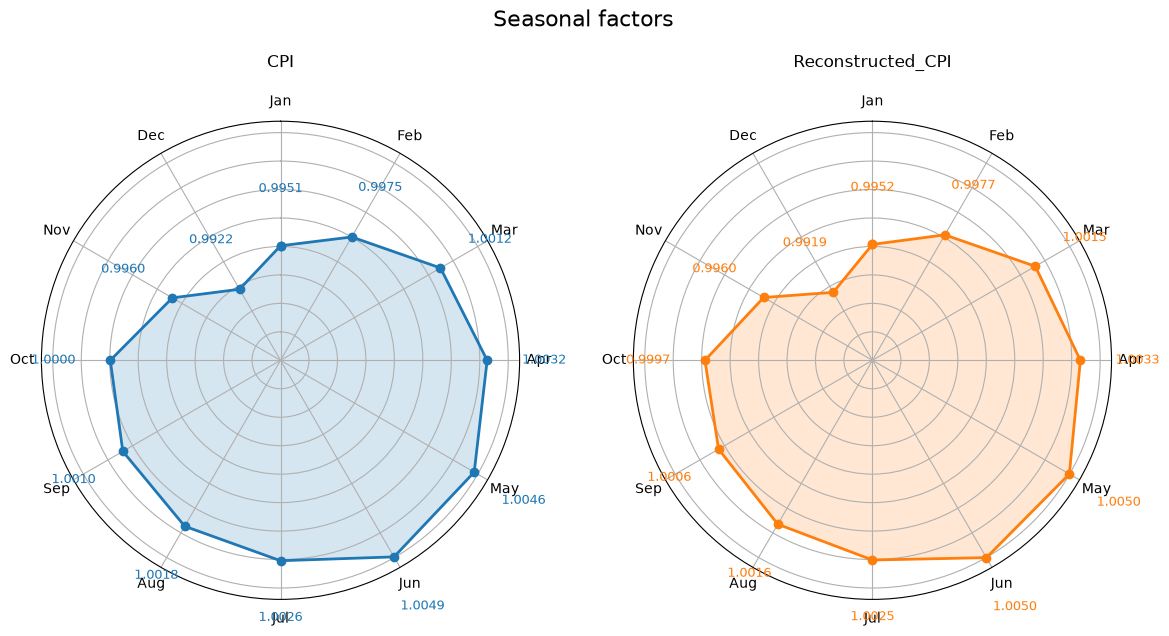

In [93]:
import math
import numpy as np
import matplotlib.pyplot as plt

selected_items = [
    "CPI",
    "Reconstructed_CPI"
]

plot_df = one_set_of_factors[selected_items].copy()

month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
angles = np.linspace(0, 2 * np.pi, len(month_labels), endpoint=False)
angles = np.append(angles, angles[0])

n_items = len(selected_items)
ncols = 2
nrows = math.ceil(n_items / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(6 * ncols, 6 * nrows),
    subplot_kw={"polar": True}
)

fig.suptitle("Seasonal factors", fontsize=16, y=1.02)

axes = np.array(axes).reshape(-1)
colors = ["tab:blue", "tab:orange"]

for i, item in enumerate(selected_items):
    ax = axes[i]
    values = plot_df[item].to_numpy(dtype=float)
    values_closed = np.append(values, values[0])

    color = colors[i % len(colors)]

    ax.plot(
        angles,
        values_closed,
        color=color,
        linewidth=2,
        marker="o"
    )
    ax.fill(
        angles,
        values_closed,
        color=color,
        alpha=0.18
    )

    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(month_labels)

    ax.set_ylim(0.985, 1.006)
    ax.set_yticklabels([])
    ax.grid(True)

    ax.set_title(item, pad=20)

    for angle, value in zip(angles[:-1], values):
        ax.text(
            angle,
            value + 0.005,
            f"{value:.4f}",
            ha="center",
            va="center",
            fontsize=9,
            color=color
        )

for j in range(n_items, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()